# Member 1 — Business Understanding, EDA & Disagreement Atlas
**IT3091 Machine Learning — TRIAGE-Telco / Group 2026-DS-07**  
**Responsible member:** Jayasinghe S.S. (IT24102186)  
**Scope:** Business framing; data quality; visual EDA; correlation/association; customer-group contradictions; disagreement profiling

**What is calculated afresh:** dataset checks, distributions, heatmaps, subgroup Wilson intervals and Atlas group summaries. **What is loaded:** saved development out-of-fold model predictions for the Atlas and the original EDA decision log.

**How to run:** Extract the entire four-folder ZIP, install `final_notebook_code/requirements.txt`, and open this notebook from the project folder. Use **Kernel → Restart & Run All**. It reads the original CSV and archived evidence from the folder tree; it does **not** need any other notebook to have run first.

**Evidence boundary:** The historical full-data EDA is descriptive; recorded test results are a historical replay with disclosed prior test exposure; reused development folds make tuning scores potentially optimistic. Notebook sections label archived experimental evidence separately from computations performed when you run the notebook.


In [1]:
from pathlib import Path
import pandas as pd, numpy as np, matplotlib.pyplot as plt
from IPython.display import display
from scipy.stats import chi2_contingency
print('Member 1: EDA using the original dataset and saved out-of-fold evidence')

Member 1: EDA using the original dataset and saved out-of-fold evidence


In [2]:
# Load the original project files directly. Nothing is compressed or hidden in this notebook.
# Open the notebook from the submission root OR from final_notebook_code/.
from pathlib import Path

def locate_project_root():
    current = Path.cwd().resolve()
    candidates = [current, current.parent, current.parent.parent]
    for base in candidates:
        if (base / 'dataset' / 'raw' / 'WA_Fn-UseC_-Telco-Customer-Churn.csv').exists() and (base / 'model_method_comparison').is_dir():
            return base
    raise FileNotFoundError(
        'Project files not found. Extract the entire ZIP first, then run Jupyter from '
        'the submission folder or final_notebook_code folder. Do not open only the .ipynb.'
    )

PROJECT_ROOT = locate_project_root()
FILES = {
    'raw_csv': 'dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv',
    'split': 'dataset/splits/split_membership.csv',
    'folds': 'dataset/splits/cv_fold_membership.csv',
    'dictionary': 'dataset/DATA_DICTIONARY.csv',
    'eda_log': 'decision_logs/member1/EDA_INSIGHT_LOG.csv',
    'prep_log': 'decision_logs/member2/preprocessing_decision_log.csv',
    'feature_log': 'decision_logs/member2/feature_registry.csv',
    'decision_log': 'decision_logs/project/CONSOLIDATED_DECISION_LOG.csv',
    'models_summary': 'model_method_comparison/MODEL_METHOD_COMPARISON.csv',
    'preprocess_pred': 'model_method_comparison/handoffs/member2_to_member3/OOF_preprocessing_predictions.csv',
    'oof': 'model_method_comparison/handoffs/member3_to_member4/candidate_models_updated_oof.csv',
    'stability': 'model_method_comparison/handoffs/member3_to_member4/customer_stability_integrated_development.csv',
    'generalization': 'model_method_comparison/results/member3/generalization_audit/model_generalization_summary.csv',
    'tolerance': 'model_method_comparison/results/member3/tables/near_optimal_tolerance_comparison.csv',
    'recorded_test': 'model_method_comparison/results/member4/final_test_probabilities_20261002_100144.csv',
    'scorecard': 'model_method_comparison/results/member4/final_test_scorecard.csv',
    'synthetic': 'dataset/examples/synthetic_customers.csv',
    'tc_treatment': 'model_method_comparison/results/member2/tables/totalcharges_treatment_results.csv',
    'balance': 'model_method_comparison/results/member2/tables/imbalance_arena_results.csv',
    'features': 'model_method_comparison/results/member2/tables/feature_ablation_results.csv',
    'demographic': 'model_method_comparison/results/member2/tables/data_minimization_results.csv',
}

def source_csv(name):
    '''Read one of the original recorded CSVs from the four submission folders.'''
    return pd.read_csv(PROJECT_ROOT / FILES[name])

raw = source_csv('raw_csv')
split = source_csv('split')
folds = source_csv('folds')
assert raw.shape == (7043, 21) and raw.customerID.is_unique
assert len(split) == len(raw) and len(folds) == 5634
print('Project folder:', PROJECT_ROOT)
print('Original Telco CSV:', FILES['raw_csv'])
print('Dataset size:', raw.shape, '| Development folds:', len(folds))
display(raw.head(3))


Project folder: /mnt/data/TRIAGE_Telco_FINAL_FOUR_MEMBER_NOTEBOOKS
Original Telco CSV: dataset/raw/WA_Fn-UseC_-Telco-Customer-Churn.csv
Dataset size: (7043, 21) | Development folds: 5634


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes


## 1. Business question and dataset quality
**Decision:** Identify churn patterns and data problems that might affect a retention decision. These are associations rather than causal explanations.

In [3]:
eda = raw.copy()
eda['ChurnFlag'] = eda.Churn.eq('Yes').astype(int)
eda['TotalCharges_num'] = pd.to_numeric(eda.TotalCharges,errors='coerce')
blank = eda.TotalCharges.astype(str).str.strip().eq('')
quality = pd.DataFrame({'Check':['Customers','Original fields','Unique customer IDs','Exact duplicate rows','Churners','Churn share','Blank TotalCharges','Blank TotalCharges at tenure=0'],
 'Result':[len(eda),len(raw.columns),raw.customerID.nunique(),int(raw.duplicated().sum()),int(eda.ChurnFlag.sum()),f'{eda.ChurnFlag.mean():.2%}',int(blank.sum()),int((blank & eda.tenure.eq(0)).sum())]})
display(quality)
assert blank.sum()==11 and eda.loc[blank,'tenure'].eq(0).all()
print('Data-quality decision: 11 structural zero-tenure charge blanks require explicit treatment, not silent row deletion.')

,Check,Result
0,Customers,7043
1,Original fields,21
2,Unique customer IDs,7043
3,Exact duplicate rows,0
4,Churners,1869
5,Churn share,26.54%
6,Blank TotalCharges,11
7,Blank TotalCharges at tenure=0,11


Data-quality decision: 11 structural zero-tenure charge blanks require explicit treatment, not silent row deletion.


**EDA questions:** Which contract types churn more? How does tenure interact with charges? Does fiber-optic churn vary across contracts? These findings guide modelling, but the training pipeline must not be fitted on the complete dataset.

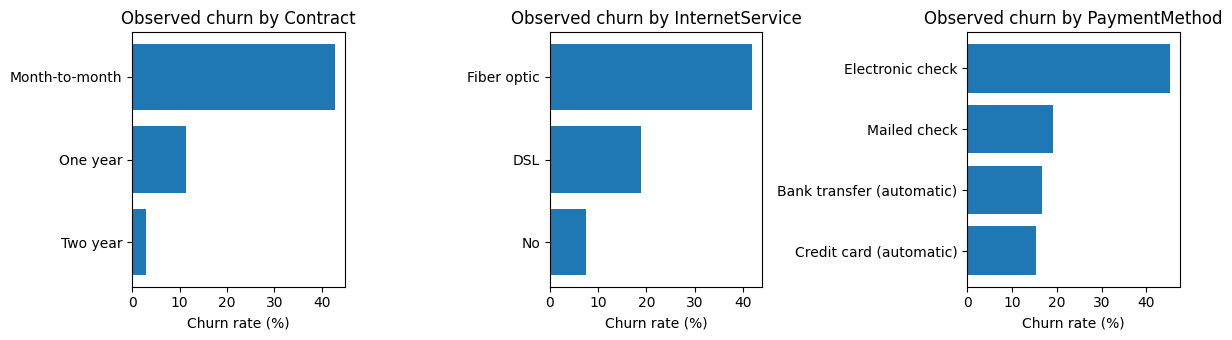

Contract,Month-to-month,One year,Two year
Internet service,,,
DSL,32.2,9.3,1.9
Fiber optic,54.6,19.3,7.2
No,18.9,2.5,0.8


In [4]:
fig,ax=plt.subplots(1,3,figsize=(12,3.5))
for a,col in zip(ax,['Contract','InternetService','PaymentMethod']):
 rates=eda.groupby(col).ChurnFlag.agg(['mean','size']).sort_values('mean',ascending=False)
 a.barh(rates.index.astype(str),rates['mean']*100)
 a.invert_yaxis();a.set_title(f'Observed churn by {col}');a.set_xlabel('Churn rate (%)')
plt.tight_layout();plt.show()
relationship=eda.pivot_table(index='InternetService',columns='Contract',values='ChurnFlag',aggfunc='mean')
display((relationship*100).round(1).rename_axis('Internet service'))

**Correlation and categorical associations.** Pearson correlation is appropriate for numeric measurements; many service/contract fields are categorical, so their association strength is shown using bias-corrected Cramér’s V. Correlation and association are **not causal evidence**.

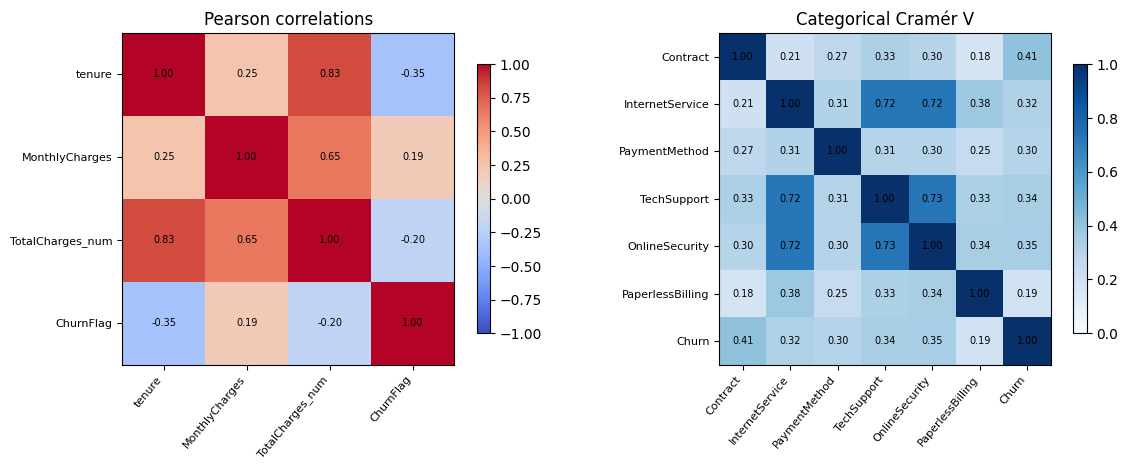

tenure vs TotalCharges Pearson: 0.826 | Contract vs Churn Cramér V: 0.41


In [5]:
numeric=eda[['tenure','MonthlyCharges','TotalCharges_num','ChurnFlag']].corr()
def cramers_v(a,b):
    tab=pd.crosstab(a,b)
    chi2=chi2_contingency(tab,correction=False)[0]; n=tab.to_numpy().sum()
    phi2=chi2/n; r,k=tab.shape
    phi2corr=max(0,phi2-(k-1)*(r-1)/(n-1))
    rcorr=r-(r-1)**2/(n-1);kcorr=k-(k-1)**2/(n-1)
    return np.sqrt(phi2corr/max(min(kcorr-1,rcorr-1),1e-15))
cats=['Contract','InternetService','PaymentMethod','TechSupport','OnlineSecurity','PaperlessBilling','Churn']
cvmat=pd.DataFrame([[cramers_v(eda[a],eda[b]) for b in cats] for a in cats],index=cats,columns=cats)
fig,axs=plt.subplots(1,2,figsize=(12,4.8))
for axis,mat,title,vmax in [(axs[0],numeric,'Pearson correlations',1),(axs[1],cvmat,'Categorical Cramér V',1)]:
 img=axis.imshow(mat,vmin=-1 if title.startswith('Pearson') else 0,vmax=vmax,cmap='coolwarm' if title.startswith('Pearson') else 'Blues')
 axis.set_xticks(range(len(mat)));axis.set_xticklabels(mat.columns,rotation=50,ha='right',fontsize=8)
 axis.set_yticks(range(len(mat)));axis.set_yticklabels(mat.index,fontsize=8)
 for (i,j),x in np.ndenumerate(mat.to_numpy()):axis.text(j,i,f'{x:.2f}',ha='center',va='center',fontsize=7)
 axis.set_title(title);fig.colorbar(img,ax=axis,fraction=.03)
plt.tight_layout();plt.show()
print('tenure vs TotalCharges Pearson:',round(numeric.loc['tenure','TotalCharges_num'],3),'| Contract vs Churn Cramér V:',round(cvmat.loc['Contract','Churn'],3))

In [6]:
eda_log=source_csv('eda_log')
dictionary=source_csv('dictionary')
display(dictionary.head(8))
display(eda_log.head(6))

,column,meaning,raw_dtype,n_unique,role,allowed_use,sample_values,caveat
0,customerID,Unique customer identifier,object,7043,Identifier,Join/tracking only,7590-VHVEG | 5575-GNVDE | 3668-QPYBK | 7795-CF...,Do not use as a behavioural predictor.
1,gender,Customer gender,object,2,Demographic/context,Predictor in full reference; data-minimisation...,Female | Male,Do not treat as an actionable retention lever.
2,SeniorCitizen,Senior-citizen indicator (0/1),int64,2,Demographic/context,Predictor in full reference; data-minimisation...,0 | 1,Conceptually categorical although stored as in...
3,Partner,Whether the customer has a partner,object,2,Customer profile,Predictor candidate,Yes | No,Association is not causal.
4,Dependents,Whether the customer has dependents,object,2,Customer profile,Predictor candidate,No | Yes,Association is not causal.
5,tenure,Months with the provider,int64,73,Relationship/history,Predictor candidate,1 | 34 | 2 | 45 | 8 | 22,History variable; cannot be changed retroactiv...
6,PhoneService,Whether phone service is active,object,2,Service,Predictor candidate,No | Yes,Upstream service state.
7,MultipleLines,Multiple phone lines status,object,3,Service,Predictor candidate,No phone service | No | Yes,"""No phone service"" is structural, not missing."


,ID,Question,Population_n,Evidence,Insight,Caveat,Next_action,Confidence
0,EDA-01,Does contract relate to churn?,7043,Churn rate + n by Contract; Wilson CI; bootstr...,Month-to-month churn=42.7% vs Two-year=2.8%.,Contract is related to tenure/service mix; ass...,Retain for modelling; interpret jointly with t...,HIGH
1,EDA-02,Are new customers riskier?,7043,Tenure-band churn rates + churn-group numeric ...,0-6 month churn=52.9%; 49-72 month churn=9.5%.,EDA band cut-points are analyst choices.,Keep tenure continuous for modelling; bands ar...,HIGH
2,EDA-03,Does payment method identify risk?,7043,Overall PaymentMethod rates + Contract×Payment...,Electronic check overall churn=45.3%; relation...,Payment method may reflect self-selection/cust...,Let Member 2 preserve category meaning; Member...,HIGH
3,EDA-04,Does Fiber optic context matter?,7043,InternetService rates + Contract×InternetServi...,"Fiber optic overall churn=41.9%, but absolute ...",Internet service may proxy service package/cha...,Test interaction-sensitive models; avoid a one...,HIGH
4,EDA-05,Is TechSupport associated with churn?,7043,TechSupport churn rates + bootstrap contrast,TechSupport=No churn=41.6% vs Yes=15.2%.,"""No internet service"" is a separate structural...",Preserve structural categories; test SupportGa...,HIGH
5,EDA-06,How do numeric customer histories differ by ch...,7043,Median/mean numeric summary by Churn + boxplots,Median tenure: churners=10m vs non-churners=38...,TotalCharges is confounded by tenure; lower cu...,Member 2 should keep numeric meaning and test ...,HIGH


### 1.1 Mixed-signal profiles + uncertainty
Example: fiber-optic service is often associated with higher churn, while two-year contracts are associated with lower churn. Both can describe the **same person**. Compare their actual historic rates before assigning a simplistic rule.

In [7]:
fiber=eda.InternetService.eq('Fiber optic'); two_year=eda.Contract.eq('Two year')
from math import sqrt

def wilson(k,n,z=1.96):
    p=k/n; den=1+z*z/n
    center=(p+z*z/(2*n))/den
    half=z*sqrt((p*(1-p)+z*z/(4*n))/n)/den
    return max(0,center-half),min(1,center+half)
rows=[]
for name,mask in [('All fiber optic',fiber),('Fiber optic + two year contract',fiber & two_year),('All month-to-month',eda.Contract.eq('Month-to-month'))]:
 n=int(mask.sum());k=int(eda.loc[mask,'ChurnFlag'].sum());lo,hi=wilson(k,n)
 rows.append([name,n,k,round(k/n,4),round(lo,4),round(hi,4)])
display(pd.DataFrame(rows,columns=['Customer profile','n','churners','observed rate','Wilson low','Wilson high']))
print('Note: these are historical subgroup associations; searching many groups can produce chance patterns.')

,Customer profile,n,churners,observed rate,Wilson low,Wilson high
0,All fiber optic,3096,1297,0.4189,0.4017,0.4364
1,Fiber optic + two year contract,429,31,0.0723,0.0514,0.1007
2,All month-to-month,3875,1655,0.4271,0.4116,0.4427


Note: these are historical subgroup associations; searching many groups can produce chance patterns.


## 2. Disagreement Atlas — returning model predictions to EDA
Member 3 provided saved out-of-fold (OOF) predictions. Here we link each development customer to their contract type and calculate whether **four model families** disagree at diagnostic threshold **0.50**. This is not the final operational threshold of 0.35.

In [8]:
fold_order=folds.sort_values('DevelopmentOrder').customerID
recorded_oof=source_csv('oof').set_index('customerID').loc[fold_order].reset_index()
family=['prob_Logistic_Regression','prob_Gradient_Boosting','prob_Tuned_Random_Forest','prob_Tuned_CatBoost']
family_flip=recorded_oof[family].ge(0.50).nunique(axis=1).gt(1)
pre_p=source_csv('preprocess_pred').set_index('customerID').loc[fold_order].reset_index()
prep_unstable=pre_p.prep_any_disagreement.astype(bool)
assert int(family_flip.sum())==463
assert int(prep_unstable.sum())==1114
print('Four-family disagreement:',int(family_flip.sum()),'of',len(family_flip),'development customers')

Four-family disagreement: 463 of 5634 development customers


,size,sum,mean
Contract,,,
Month-to-month,3102,460,0.1483
One year,1173,3,0.0026
Two year,1359,0,0.0000


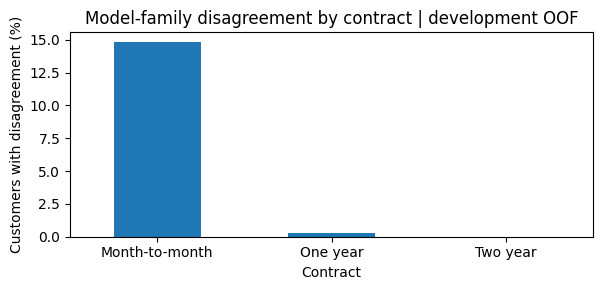

These are association summaries, not proof contract changes would improve prediction reliability.


In [9]:
atlas=raw[['customerID','Contract','InternetService','tenure','TechSupport']].merge(
    pd.DataFrame({'customerID':fold_order.to_numpy(),'family_disagreement':family_flip.to_numpy(),'prep_disagreement':prep_unstable.to_numpy()}),
    on='customerID',how='inner',validate='one_to_one')
by_contract=atlas.groupby('Contract').family_disagreement.agg(['size','sum','mean']).sort_values('mean',ascending=False)
display(by_contract.round(4))
ax=(by_contract['mean']*100).plot(kind='bar',figsize=(6,3),rot=0,title='Model-family disagreement by contract | development OOF')
ax.set_ylabel('Customers with disagreement (%)');plt.tight_layout();plt.show()
print('These are association summaries, not proof contract changes would improve prediction reliability.')

## 3. EDA handoff to Member 2
The quality log identifies **11 blank `TotalCharges` fields at zero tenure**; the original data remains unchanged. Contract, tenure, internet-service type and support options deserve testing together. This handoff informs fold-fitted preprocessing but does not predetermine the final model.

In [10]:
display(source_csv('dictionary').head(12))
display(source_csv('eda_log').head(12))
assert len(raw)==7043

,column,meaning,raw_dtype,n_unique,role,allowed_use,sample_values,caveat
0,customerID,Unique customer identifier,object,7043,Identifier,Join/tracking only,7590-VHVEG | 5575-GNVDE | 3668-QPYBK | 7795-CF...,Do not use as a behavioural predictor.
1,gender,Customer gender,object,2,Demographic/context,Predictor in full reference; data-minimisation...,Female | Male,Do not treat as an actionable retention lever.
2,SeniorCitizen,Senior-citizen indicator (0/1),int64,2,Demographic/context,Predictor in full reference; data-minimisation...,0 | 1,Conceptually categorical although stored as in...
3,Partner,Whether the customer has a partner,object,2,Customer profile,Predictor candidate,Yes | No,Association is not causal.
4,Dependents,Whether the customer has dependents,object,2,Customer profile,Predictor candidate,No | Yes,Association is not causal.
5,tenure,Months with the provider,int64,73,Relationship/history,Predictor candidate,1 | 34 | 2 | 45 | 8 | 22,History variable; cannot be changed retroactiv...
6,PhoneService,Whether phone service is active,object,2,Service,Predictor candidate,No | Yes,Upstream service state.
7,MultipleLines,Multiple phone lines status,object,3,Service,Predictor candidate,No phone service | No | Yes,"""No phone service"" is structural, not missing."
8,InternetService,Internet service type,object,3,Service,Predictor candidate,DSL | Fiber optic | No,DSL / Fiber optic / No.
9,OnlineSecurity,Online security add-on status,object,3,Add-on service,Predictor candidate,No | Yes | No internet service,"""No internet service"" is structural, not missing."


,ID,Question,Population_n,Evidence,Insight,Caveat,Next_action,Confidence
0,EDA-01,Does contract relate to churn?,7043,Churn rate + n by Contract; Wilson CI; bootstr...,Month-to-month churn=42.7% vs Two-year=2.8%.,Contract is related to tenure/service mix; ass...,Retain for modelling; interpret jointly with t...,HIGH
1,EDA-02,Are new customers riskier?,7043,Tenure-band churn rates + churn-group numeric ...,0-6 month churn=52.9%; 49-72 month churn=9.5%.,EDA band cut-points are analyst choices.,Keep tenure continuous for modelling; bands ar...,HIGH
2,EDA-03,Does payment method identify risk?,7043,Overall PaymentMethod rates + Contract×Payment...,Electronic check overall churn=45.3%; relation...,Payment method may reflect self-selection/cust...,Let Member 2 preserve category meaning; Member...,HIGH
3,EDA-04,Does Fiber optic context matter?,7043,InternetService rates + Contract×InternetServi...,"Fiber optic overall churn=41.9%, but absolute ...",Internet service may proxy service package/cha...,Test interaction-sensitive models; avoid a one...,HIGH
4,EDA-05,Is TechSupport associated with churn?,7043,TechSupport churn rates + bootstrap contrast,TechSupport=No churn=41.6% vs Yes=15.2%.,"""No internet service"" is a separate structural...",Preserve structural categories; test SupportGa...,HIGH
5,EDA-06,How do numeric customer histories differ by ch...,7043,Median/mean numeric summary by Churn + boxplots,Median tenure: churners=10m vs non-churners=38...,TotalCharges is confounded by tenure; lower cu...,Member 2 should keep numeric meaning and test ...,HIGH
6,EDA-07,Do simple risk stories break under context?,7043,Contradiction profile table,Several mixed-signal profiles show churn rates...,Profiles were chosen using EDA evidence and sh...,Member 3 should compare model disagreement for...,MEDIUM
7,EDA-08,Are there exceptional two-way customer subgroups?,7043,Leakage-safe two-way subgroup screen with mini...,Several interpretable groups have churn lift w...,Multiple-comparison discovery can produce chan...,Shortlist only interpretable/large groups; val...,MEDIUM
8,EDA-09,Are key descriptive differences stable to resa...,7043,500-sample bootstrap stability table for four ...,Major contract/payment/support/internet contra...,Bootstrap stability is not proof of causality ...,"Use as evidence-confidence tag, not as a model...",HIGH
9,EDA-10,Are demographic variables appropriate action l...,7043,Descriptive subgroup rates for gender and Seni...,Demographics can be audited descriptively but ...,Fairness and necessity require later evaluation.,Pass to Member 4 for subgroup error/fairness a...,MEDIUM


## Member handoff and interpretation
This member notebook is a **stand-alone view** of one part of the shared project. It duplicates the minimum setup needed to run independently. The integrated notebook provides the complete sequential view across Members 1–4. Detailed decision logs and archived results remain in the `decision_logs/` and `model_method_comparison/` folders.

**Do not report saved evidence as a newly rerun search** if the notebook only loads the existing result CSV. Assessments of business benefit require new intervention-outcome data; model agreement is not a correctness guarantee.
